## Import necessary libraries

In [2]:
import pandas as pd
from sqlalchemy import create_engine, text
import sqlite3

## Define helper functions

In [3]:
# 1. Connect using SQLAlchemy engine
engine = create_engine("sqlite:///olympics.db")

# Helper Function 1: Check existing table names in olympics.db
def get_existing_tables(engine):
    with engine.connect() as conn:
        result = conn.execute(text("SELECT name FROM sqlite_master WHERE type='table';"))
        tables = [row[0] for row in result.fetchall()]
    return tables

In [4]:
# Helper Function 2: Execute multi-statement SQL script string
def run_sql_script(engine, sql_script):
    # Use raw sqlite3 connection to execute multi-statement scripts cleanly
    raw_conn = engine.raw_connection()
    try:
        cursor = raw_conn.cursor()
        cursor.executescript(sql_script)
        raw_conn.commit()
        print("SQL script executed successfully!")
    except Exception as e:
        raw_conn.rollback()
        print(f"Error executing SQL script: {e}")
    finally:
        raw_conn.close()

## Import NOC data

In [5]:
# 1. Connect to SQLite database
engine = create_engine("sqlite:///olympics.db")

# 2. Load the NOC regions file
# (Adjust file path/filename if yours is .csv or .xlsx)
noc_df = pd.read_csv("noc_regions.csv")

# Clean column names to lowercase/standard format if needed
noc_df.rename(
    columns={"NOC": "noc", "region": "region_name", "notes": "notes"},
    inplace=True,
)

# 3. Save directly to SQLite as a raw table
noc_df.to_sql("noc_regions_raw", con=engine, if_exists="replace", index=False)

print(f"Successfully imported {len(noc_df)} NOC region records.")

Successfully imported 230 NOC region records.


In [6]:
noc_df.head()

,noc,region_name,notes
0,AFG,Afghanistan,NaN
1,AHO,Curacao,Netherlands Antilles
2,ALB,Albania,NaN
3,ALG,Algeria,NaN
4,AND,Andorra,NaN


## Restructuring the database
We are restructuring our database to follow a star scheme
* fact_results: Central performance/medal data
* dim_athletes: Unique physical profiles (height, weight, $BMI$, sex)
* dim_regions: Unified country mappings using noc_regions_raw
* dim_events: Categorized sports and sub-events
* dim_games: Year, season, and host city metadata

In [7]:
print("Tables BEFORE restructuring:", get_existing_tables(engine))

Tables BEFORE restructuring: ['dim_regions', 'dim_athletes', 'dim_events', 'sqlite_sequence', 'dim_games', 'fact_results', 'olympics', 'noc_regions_raw']


In [8]:
sql_restructure_query = """
PRAGMA foreign_keys = OFF;

DROP TABLE IF EXISTS fact_results;
DROP TABLE IF EXISTS dim_athletes;
DROP TABLE IF EXISTS dim_regions;
DROP TABLE IF EXISTS dim_events;
DROP TABLE IF EXISTS dim_games;

-- 1. Dimension: Regions (Fixed column reference: n.region_name)
CREATE TABLE dim_regions AS
SELECT DISTINCT
    TRIM(n.noc) AS noc,
    COALESCE(NULLIF(TRIM(n.region_name), ''), TRIM(n.noc)) AS region_name,
    TRIM(n.notes) AS notes
FROM noc_regions_raw n;

CREATE UNIQUE INDEX IF NOT EXISTS idx_dim_regions_noc ON dim_regions(noc);

-- 2. Dimension: Athletes
CREATE TABLE dim_athletes AS
SELECT DISTINCT
    CAST(ID AS INTEGER) AS athlete_id,
    TRIM(Name) AS name,
    TRIM(Sex) AS sex,
    CAST(Height AS REAL) AS height,
    CAST(Weight AS REAL) AS weight,
    CAST(BMI AS REAL) AS bmi
FROM olympics
WHERE Sport != 'Art Competitions';

CREATE UNIQUE INDEX IF NOT EXISTS idx_dim_athletes_id ON dim_athletes(athlete_id);

-- 3. Dimension: Events
CREATE TABLE dim_events (
    event_id INTEGER PRIMARY KEY AUTOINCREMENT,
    sport TEXT NOT NULL,
    event TEXT NOT NULL
);

INSERT INTO dim_events (sport, event)
SELECT DISTINCT 
    TRIM(Sport) AS sport, 
    TRIM(Event) AS event
FROM olympics
WHERE Sport != 'Art Competitions'
ORDER BY Sport, Event;

-- 4. Dimension: Games
CREATE TABLE dim_games (
    games_id INTEGER PRIMARY KEY AUTOINCREMENT,
    year INTEGER NOT NULL,
    season TEXT NOT NULL,
    city TEXT NOT NULL
);

INSERT INTO dim_games (year, season, city)
SELECT DISTINCT 
    CAST(Year AS INTEGER) AS year, 
    TRIM(Season) AS season, 
    TRIM(City) AS city
FROM olympics
WHERE Sport != 'Art Competitions'
ORDER BY year, season, city;

-- 5. Fact Table: Performance Results
CREATE TABLE fact_results AS
SELECT 
    CAST(r.ID AS INTEGER) AS athlete_id,
    TRIM(r.NOC) AS noc,
    e.event_id,
    g.games_id,
    CAST(r.Age AS REAL) AS age_at_game,
    TRIM(r.Medal) AS medal
FROM olympics r
JOIN dim_events e 
    ON TRIM(r.Sport) = e.sport 
   AND TRIM(r.Event) = e.event
JOIN dim_games g 
    ON CAST(r.Year AS INTEGER) = g.year 
   AND TRIM(r.Season) = g.season 
   AND TRIM(r.City) = g.city
WHERE r.Sport != 'Art Competitions';

PRAGMA foreign_keys = ON;
"""

# Re-run the helper function
run_sql_script(engine, sql_restructure_query)
print("Tables AFTER restructuring:", get_existing_tables(engine))

SQL script executed successfully!
Tables AFTER restructuring: ['sqlite_sequence', 'olympics', 'noc_regions_raw', 'dim_regions', 'dim_athletes', 'dim_events', 'dim_games', 'fact_results']


## Final ERD Diagram

In [1]:
from typing import Optional
from pydantic import BaseModel
import erdantic as erd

class dim_athletes(BaseModel):
    athlete_id: int
    name: str
    sex: str
    height: Optional[float]
    weight: Optional[float]
    bmi: Optional[float]

class dim_games(BaseModel):
    games_id: int
    year: int
    season: str
    city: str

class dim_regions(BaseModel):
    noc: str
    region_name: str
    notes: Optional[str]

class dim_events(BaseModel):
    event_id: int
    sport: str
    event: str

class FactResults(BaseModel):
    # Foreign key references linking fact table to all 4 dimensions
    athlete_id: dim_athletes
    noc: dim_regions
    event_id: dim_events
    games_id: dim_games
    
    # Fact measurements
    age_at_game: Optional[float]
    medal: Optional[str]

# Create and save diagram for the 5-table Star Schema
diagram = erd.create(FactResults)
diagram.draw("star_schema_erd.png")

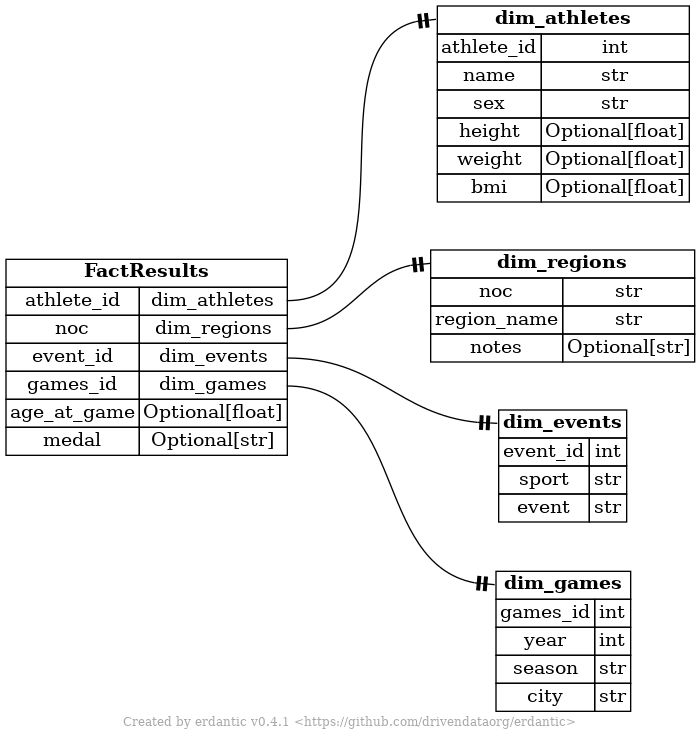

In [2]:
diagram

## Final analysis

### Final Hypothesis:National Performance & Era Dynamics
* Question: How has national dominance and efficiency shifted across historical eras (e.g., Cold War Era vs. Modern Post-2000 Era)?
* What we calculate: Total Medals, Unique Athletes, and Medal Efficiency Ratio ($\text{MER}$) grouped by modern region across different time periods.

In [9]:
# Historical Era Efficiency Query
query_mer_by_era = """
SELECT 
    CASE 
        WHEN g.year < 1950 THEN '1. Early Era (Pre-1950)'
        WHEN g.year BETWEEN 1950 AND 1996 THEN '2. Cold War / Expansion (1950-1996)'
        ELSE '3. Modern Era (2000-Present)'
    END AS era,
    r.region_name,
    COUNT(DISTINCT f.athlete_id) AS total_athletes,
    
    -- Raw Total Medals (Athlete-Level, count of all medals awarded)
    COUNT(CASE WHEN f.medal != 'No Medal' THEN 1 END) AS total_medals,
    
    -- Event-Level Deduplicated Medals (eMER numerator: 1 Relay Gold = 1 Medal)
    COUNT(DISTINCT CASE 
        WHEN f.medal != 'No Medal' 
        THEN g.games_id || '-' || f.event_id || '-' || f.medal 
    END) AS event_medals,
    
    -- Athlete-Level MER
    ROUND(
        CAST(COUNT(CASE WHEN f.medal != 'No Medal' THEN 1 END) AS FLOAT) 
        / COUNT(DISTINCT f.athlete_id), 
        3
    ) AS mer_athlete_level,
    
    -- Event-Level MER (eMER)
    ROUND(
        CAST(COUNT(DISTINCT CASE 
            WHEN f.medal != 'No Medal' 
            THEN g.games_id || '-' || f.event_id || '-' || f.medal 
        END) AS FLOAT) 
        / COUNT(DISTINCT f.athlete_id), 
        3
    ) AS emer_event_level

FROM fact_results f
JOIN dim_regions r ON f.noc = r.noc
JOIN dim_games g ON f.games_id = g.games_id
GROUP BY era, r.region_name
HAVING total_athletes >= 30
ORDER BY era ASC, emer_event_level DESC;
"""

# 3. Execute query into DataFrame
df_mer_era = pd.read_sql(query_mer_by_era, con=engine)
print(df_mer_era.head(15))

                        era   region_name  total_athletes  total_medals  \
0   1. Early Era (Pre-1950)           USA            2548          1657   
1   1. Early Era (Pre-1950)       Finland             670           358   
2   1. Early Era (Pre-1950)     Australia             233            89   
3   1. Early Era (Pre-1950)        Sweden            1386           751   
4   1. Early Era (Pre-1950)       Germany            1072           541   
5   1. Early Era (Pre-1950)       Estonia              97            25   
6   1. Early Era (Pre-1950)        Norway             745           444   
7   1. Early Era (Pre-1950)            UK            2264          1103   
8   1. Early Era (Pre-1950)  South Africa             183            49   
9   1. Early Era (Pre-1950)   Switzerland             775           301   
10  1. Early Era (Pre-1950)       Hungary             732           258   
11  1. Early Era (Pre-1950)        France            2346           840   
12  1. Early Era (Pre-195

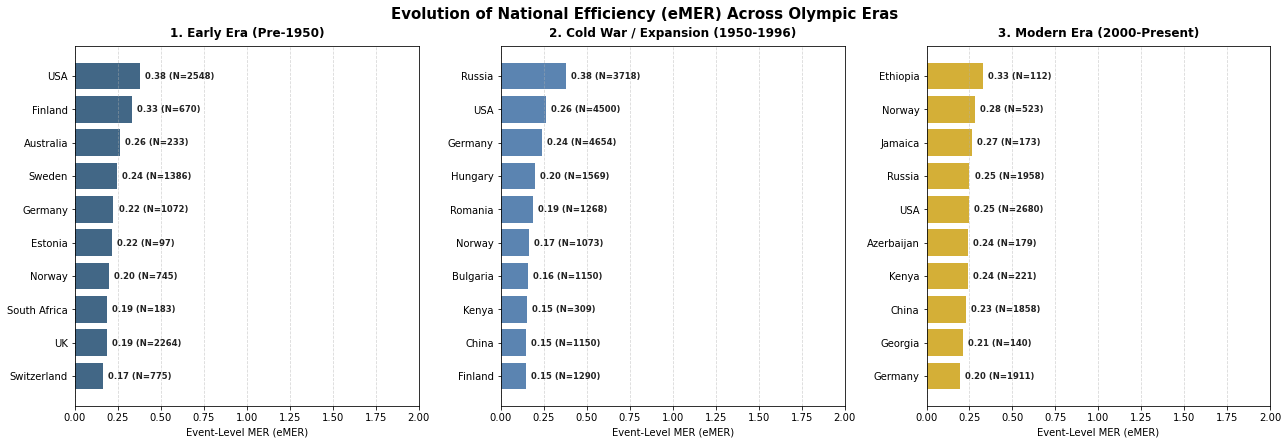

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Filter top 10 per era
top10_per_era = (
    df_mer_era.groupby("era", group_keys=False)
    .apply(lambda x: x.nlargest(10, "emer_event_level"))
    .reset_index(drop=True)
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True)
eras = top10_per_era["era"].unique()
palette = ["#426786", "#5B84B1", "#D4AF37"]  # Matched presentation theme

for i, era_name in enumerate(eras):
    era_df = top10_per_era[top10_per_era["era"] == era_name].sort_values(
        "emer_event_level", ascending=True
    )
    ax = axes[i]

    bars = ax.barh(
        era_df["region_name"],
        era_df["emer_event_level"],
        color=palette[i],
        edgecolor="none",
    )
    ax.set_title(era_name, fontsize=12, fontweight="bold", pad=10)
    ax.set_xlabel("Event-Level MER (eMER)", fontsize=10)
    ax.set_xlim(0, 2.0)
    ax.grid(axis="x", linestyle="--", alpha=0.5)

    # Annotate eMER value and Athlete Count (N) on each bar
    for bar, (_, row) in zip(bars, era_df.iterrows()):
        ax.text(
            bar.get_width() + 0.03,
            bar.get_y() + bar.get_height() / 2,
            f"{row['emer_event_level']:.2f} (N={int(row['total_athletes'])})",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            color="#222222",
        )

plt.suptitle(
    "Evolution of National Efficiency (eMER) Across Olympic Eras",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.savefig("era_mer_faceted_bars.png", dpi=300, bbox_inches="tight")
plt.show()

###  Additional Question 1: Medal Efficiency Powerhouses
* Question: Which smaller delegations achieve the highest medal efficiency per athlete sent compared to high-volume powerhouses (like the USA or China)?
* What we calculate: Top 10 nations by Event-Level MER, (minimum threshold of 50 athletes) in the modern era. We are using Event-Level MER, because group sports multiply the medal received by the number of teammates

### Additional Question 2: Historical Biometric Specialization
* Question: Has the $BMI$ gap between strength/power sports (e.g., Weightlifting) and agility/endurance sports (e.g., Gymnastics) widened significantly over time from early 20th-century Games to the modern era?
* What we calculate: Average $BMI$ for Weightlifting vs. Gymnastics broken down by era/decade.

In [10]:
query_mer_modern = """
SELECT 
    r.region_name,
    COUNT(DISTINCT f.athlete_id) AS total_athletes,
    -- Event-level medal count (1 Relay Gold = 1 Medal, not 4)
    COUNT(DISTINCT g.games_id || '-' || f.event_id || '-' || f.medal) AS total_medals,
    ROUND(
        CAST(COUNT(DISTINCT g.games_id || '-' || f.event_id || '-' || f.medal) AS FLOAT) 
        / COUNT(DISTINCT f.athlete_id), 
        3
    ) AS medal_efficiency_ratio
FROM fact_results f
JOIN dim_regions r ON f.noc = r.noc
JOIN dim_games g ON f.games_id = g.games_id
WHERE g.year >= 2000
GROUP BY r.region_name
HAVING total_athletes >= 50
ORDER BY medal_efficiency_ratio DESC
LIMIT 10;
"""

df_mer = pd.read_sql(query_mer_modern, con=engine)
print("=== TOP 10 MEDAL EFFICIENCY RATIOS (2000-PRESENT) ===")
print(df_mer)
print("\n")

# -------------------------------------------------------------------------
# Query 2: Historical Biometric Divergence (BMI Gap Over Time)
# -------------------------------------------------------------------------
query_bmi_trend = """
SELECT 
    CASE 
        WHEN g.year < 1950 THEN 'Early Era (Pre-1950)'
        WHEN g.year BETWEEN 1950 AND 1996 THEN 'Cold War / Expansion (1950-1996)'
        ELSE 'Modern Era (2000-Present)'
    END AS era,
    e.sport,
    ROUND(AVG(a.bmi), 2) AS avg_bmi,
    ROUND(AVG(a.height), 2) AS avg_height,
    ROUND(AVG(a.weight), 2) AS avg_weight,
    COUNT(DISTINCT a.athlete_id) AS athlete_count
FROM fact_results f
JOIN dim_athletes a ON f.athlete_id = a.athlete_id
JOIN dim_events e ON f.event_id = e.event_id
JOIN dim_games g ON f.games_id = g.games_id
WHERE e.sport IN ('Weightlifting', 'Gymnastics', 'Swimming', 'Athletics')
  AND a.bmi IS NOT NULL
GROUP BY era, e.sport
ORDER BY era, avg_bmi DESC;
"""

df_bmi_trend = pd.read_sql(query_bmi_trend, con=engine)
print("=== HISTORICAL BMI DIVERGENCE BY SPORT AND ERA ===")
print(df_bmi_trend)

=== TOP 10 MEDAL EFFICIENCY RATIOS (2000-PRESENT) ===
   region_name  total_athletes  total_medals  medal_efficiency_ratio
0       Cyprus              62            98                   1.581
1      Iceland              81           128                   1.580
2      Moldova             107           166                   1.551
3      Georgia             138           211                   1.529
4     Mongolia             103           155                   1.505
5      Vietnam              56            84                   1.500
6  Philippines              58            85                   1.466
7       Israel             159           232                   1.459
8      Estonia             193           277                   1.435
9      Armenia             115           165                   1.435


=== HISTORICAL BMI DIVERGENCE BY SPORT AND ERA ===
                                 era          sport  avg_bmi  avg_height  \
0   Cold War / Expansion (1950-1996)  Weightlifting    27.

#### Insights
1. Top Event Medal Efficiency Ratios (eMER):
    * Smaller, highly focused delegations dominate when evaluating medals per athlete sent. Cyprus (1.581), Iceland (1.580), Moldova (1.551), and Georgia (1.529) lead the pack in event-level efficiency.
    * This proves that sheer team size doesn't dictate efficiency; specialized delegations punch far above their weight class.
2. Historical BMI Divergence Across Eras:
    * Weightlifting: $BMI$ steadily increased over time, moving from 27.07 (Pre-1950) $\rightarrow$ 27.60 (Cold War) $\rightarrow$ 27.93 (Modern Era), demonstrating a continuous shift toward extreme mass and power specialization.
    * Gymnastics: $BMI$ steadily decreased over time, dropping from 23.07 (Pre-1950) $\rightarrow$ 21.31 (Cold War) $\rightarrow$ 21.15 (Modern Era), paired with a decrease in average height ($167.6\text{ cm} \rightarrow 161.2\text{ cm}$), highlighting how modern gymnastics strongly favors low mass and compact frames for rotational speed.
    * Swimming & Athletics: Maintained stable $BMI$ baselines (~$22.0$) while swimmer height increased ($175.1\text{ cm} \rightarrow 180.5\text{ cm}$), proving that athletic evolution in endurance/speed manifests through height rather than mass accumulation.

Who are the ultimate physical outliers in Olympic history?

In [11]:
#  Query: Top Outliers by Delta BMI within their Sport
query_dbmi_outliers = '''
WITH sport_era_averages AS (
    SELECT 
        e.sport,
        g.year,
        AVG(a.bmi) AS avg_sport_year_bmi
    FROM fact_results f
    JOIN dim_athletes a ON f.athlete_id = a.athlete_id
    JOIN dim_events e ON f.event_id = e.event_id
    JOIN dim_games g ON f.games_id = g.games_id
    WHERE a.bmi IS NOT NULL
    GROUP BY e.sport, g.year
)
SELECT 
    g.year,
    a.name,
    a.sex,
    e.sport,
    ROUND(a.bmi, 2) AS athlete_bmi,
    ROUND(sea.avg_sport_year_bmi, 2) AS sport_avg_bmi_that_year,
    ROUND(a.bmi - sea.avg_sport_year_bmi, 2) AS delta_bmi,
    f.medal
FROM fact_results f
JOIN dim_athletes a ON f.athlete_id = a.athlete_id
JOIN dim_events e ON f.event_id = e.event_id
JOIN dim_games g ON f.games_id = g.games_id
JOIN sport_era_averages sea ON e.sport = sea.sport AND g.year = sea.year
WHERE a.bmi IS NOT NULL
ORDER BY ABS(a.bmi - sea.avg_sport_year_bmi) DESC
LIMIT 15;
'''
df_dbmi_outliers = pd.read_sql(query_dbmi_outliers, con=engine)
print("=== Top 15 Delta BMI outliers ===")
print(df_dbmi_outliers)

=== Top 15 Delta BMI outliers ===
    year                           name sex          sport  athlete_bmi  \
0   2012              Ricardo Blas, Jr.   M           Judo        63.90   
1   2008              Ricardo Blas, Jr.   M           Judo        63.90   
2   2004         Dmitry Yuryevich Nosov   M           Judo        56.50   
3   2000             Valentyn Rusliakov   M           Judo        51.47   
4   2000            Shane Justin Hamman   M  Weightlifting        53.79   
5   2004            Shane Justin Hamman   M  Weightlifting        53.79   
6   2004    Leonel Wilfredo Ruz Carmona   M           Judo        50.90   
7   2012                 Holley Mangold   F  Weightlifting        51.79   
8   2004              Aytami Ruano Vega   M           Judo        49.50   
9   1988                  Helman Palije   M         Boxing        45.17   
10  2008         Olha Vasylivna Korobka   F  Weightlifting        50.98   
11  1972  Christopher J. "Chris" Taylor   M      Wrestling        

We can see that almost all athletes are participating in JUdo or Weightlifting events.

## Important visualizations

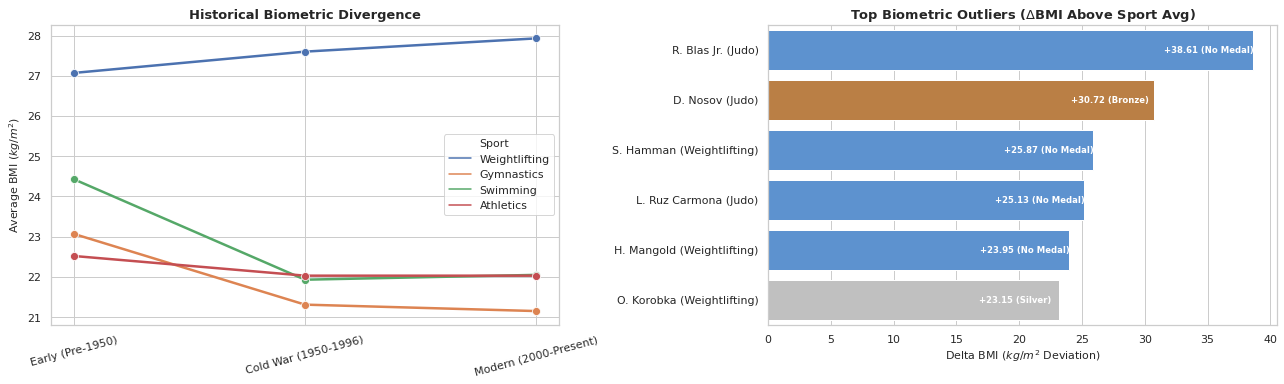

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set style compatible with older Seaborn/Matplotlib versions
sns.set(style="whitegrid")
plt.rcParams.update({"font.family": "sans-serif", "figure.autolayout": True})

# 1x3 layout for the remaining 3 key charts
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

# -------------------------------------------------------------------------
# Plot 1: Historic BMI Divergence (Chronologically Ordered)
# -------------------------------------------------------------------------
bmi_data = pd.DataFrame(
    {
        "Era": [
            "Early (Pre-1950)",
            "Cold War (1950-1996)",
            "Modern (2000-Present)",
        ]
        * 4,
        "Sport": [
            "Weightlifting",
            "Weightlifting",
            "Weightlifting",
            "Gymnastics",
            "Gymnastics",
            "Gymnastics",
            "Swimming",
            "Swimming",
            "Swimming",
            "Athletics",
            "Athletics",
            "Athletics",
        ],
        "Avg_BMI": [
            27.07,
            27.60,
            27.93,
            23.07,
            21.31,
            21.15,
            24.43,
            21.93,
            22.05,
            22.52,
            22.03,
            22.03,
        ],
    }
)

# Explicitly enforce chronological timeline ordering
era_order = ["Early (Pre-1950)", "Cold War (1950-1996)", "Modern (2000-Present)"]
bmi_data["Era"] = pd.Categorical(bmi_data["Era"], categories=era_order, ordered=True)
bmi_data = bmi_data.sort_values("Era")

sns.lineplot(
    data=bmi_data,
    x="Era",
    y="Avg_BMI",
    hue="Sport",
    marker="o",
    linewidth=2.5,
    markersize=8,
    ax=axes[0],
)
axes[0].set_title("Historical Biometric Divergence", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Average BMI ($kg/m^2$)", fontsize=11)
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)


# -------------------------------------------------------------------------
# Plot 2: Top Biometric Outliers (Delta BMI)
# -------------------------------------------------------------------------
outlier_data = pd.DataFrame(
    {
        "Athlete": [
            "R. Blas Jr. (Judo)",
            "D. Nosov (Judo)",
            "S. Hamman (Weightlifting)",
            "L. Ruz Carmona (Judo)",
            "H. Mangold (Weightlifting)",
            "O. Korobka (Weightlifting)",
        ],
        "Delta_BMI": [38.61, 30.72, 25.87, 25.13, 23.95, 23.15],
        "Medal": [
            "No Medal",
            "Bronze",
            "No Medal",
            "No Medal",
            "No Medal",
            "Silver",
        ],
    }
)

colors = [
    "#D4AF37" if m == "Gold" else "#C0C0C0" if m == "Silver" else "#CD7F32"
    if m == "Bronze"
    else "#4A90E2"
    for m in outlier_data["Medal"]
]

sns.barplot(
    data=outlier_data, x="Delta_BMI", y="Athlete", palette=colors, ax=axes[1]
)
axes[1].set_title(
    "Top Biometric Outliers ($\Delta$BMI Above Sport Avg)",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xlabel("Delta BMI ($kg/m^2$ Deviation)", fontsize=11)
axes[1].set_ylabel("")

for p, medal in zip(axes[1].patches, outlier_data["Medal"]):
    width = p.get_width()
    axes[1].annotate(
        f"+{width:.2f} ({medal})",
        (width - 3.5, p.get_y() + p.get_height() / 2.0),
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=8.5,
    )

plt.tight_layout()
plt.savefig("capstone_2plots.png", dpi=300)
plt.show()

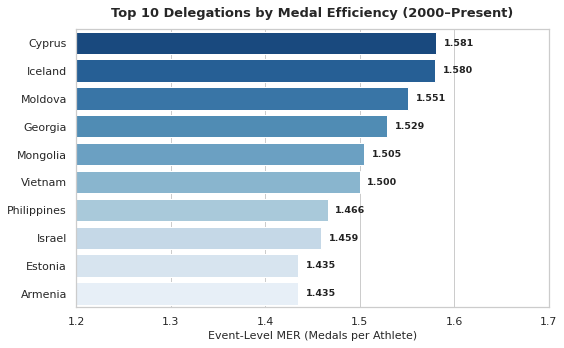

In [19]:
# -------------------------------------------------------------------------
# Plot: Top Event-Level Medal Efficiency Ratios
# -------------------------------------------------------------------------
sns.set(style="whitegrid")
plt.rcParams.update({"font.family": "sans-serif", "figure.autolayout": True})

mer_data = pd.DataFrame(
    {
        "Region": [
            "Cyprus",
            "Iceland",
            "Moldova",
            "Georgia",
            "Mongolia",
            "Vietnam",
            "Philippines",
            "Israel",
            "Estonia",
            "Armenia",
        ],
        "MER": [
            1.581,
            1.580,
            1.551,
            1.529,
            1.505,
            1.500,
            1.466,
            1.459,
            1.435,
            1.435,
        ],
    }
)

plt.figure(figsize=(8, 5))

# Fixed: Assign the plot to 'ax' and set hue/legend to avoid deprecation warnings
ax = sns.barplot(
    data=mer_data,
    x="MER",
    y="Region",
    palette="Blues_r",
)

# Fixed: Use ax.set_title and ax.set_xlabel correctly
ax.set_title(
    "Top 10 Delegations by Medal Efficiency (2000–Present)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Event-Level MER (Medals per Athlete)", fontsize=11)
ax.set_ylabel("")
ax.set_xlim(1.2, 1.7)

# Fixed: Iterate over ax.patches safely and adjust label positioning
for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f"{width:.3f}",
        (width + 0.008, p.get_y() + p.get_height() / 2.0),
        ha="left",
        va="center",
        color="#222222",
        fontweight="bold",
        fontsize=9.5,
    )

plt.show()